## FastAPI Full Course - Section 1: From Web Requests to Your First API

### 1. An Employee Management application

Imagine a website has a **Get All Employees** button. When someone clicks it, the website needs employee data. That data may live in a backend service or database.

The frontend and backend are separate parts of the system:

```text
Frontend (browser / React app)             Backend
          |                                   |
          |  "Please give me employees"       |
          | --------------------------------> |
          |                                   |
          |          Employee data            |
          | <-------------------------------- |
```

The frontend should not need to know how the backend stores or retrieves the data. It needs a defined way to ask for data and receive the result. A web API provides that interface.

Example response data:

```json
[
  {"id": 101, "name": "Ravi", "department": "IT"},
  {"id": 102, "name": "Sita", "department": "HR"}
]
```

This is example data only; it is not connected to a database yet.

## 2. What are a client and a server?

### Client

A **client** is the program or device that initiates a request for data or a service.

Examples:
- A browser
- A React, Angular, or Vue application
- A mobile application
- Postman
- Swagger UI
- Another backend service

### Server

A **server** is a program that listens for requests and sends responses. In this course, our server-side application will provide employee API endpoints.

```text
Browser / Mobile App / Postman
              |
              | request
              v
        Backend service
              |
              | response
              v
             Client
```
Examples:
Uvicorn, nginx


The words *client* and *server* describe roles in a communication. The same application can be a client in one interaction and a server in another.

## 3. What is HTTP?

**HTTP** stands for **Hypertext Transfer Protocol**. For our purposes, think of HTTP as the set of rules used to exchange requests and responses between web clients and servers.

A simplified interaction:

```text
Client                         Server
  |                               |
  | -------- HTTP request ------> |
  |                               |
  | <------- HTTP response ------ |
```

For example, a client asks for employee records. The server returns data and a status code.

HTTP is a *protocol*, not a framework or programming language. FastAPI is a framework we will use to write the application that handles HTTP requests.

## 3A. What is an API? What is a Web API?

**API** stands for **Application Programming Interface**. Think of it as an agreed way for one piece of software to ask another piece of software to do something or provide data.

Imagine a restaurant:
- You (the customer) choose what you want.
- The waiter carries your request to the kitchen.
- The kitchen prepares the food.
- The waiter brings the result back.

The waiter is an analogy for the interface: you do not need to know every detail of how the kitchen works. In software, an API defines how a consumer can interact with another system.

A **Web API** is an API exposed over web technologies, commonly HTTP/HTTPS. For example:

```text
GET https://company.example/api/employees
```

A React app, mobile app, or another backend can send a request to this endpoint and receive a response.

```text
React / Mobile App / Other Service
               |
               | HTTP request
               v
          Web API
               |
               v
      Application logic / data
               |
               v
          HTTP response
```

**Important:** An API is a general concept. Not every API is a web API; for example, a Python library's functions form an API too. In this course, when we say “API,” we usually mean a web API.

## 3B. What is a REST API?

**REST** stands for **Representational State Transfer**. It is a set of principles for designing web APIs.

In a REST API, we represent data as **resources**, such as employees, products, and orders.

### Example: Employee API

| Operation | Method and URL | Purpose |
|---|---|---|
| Get all employees | `GET /employees` | Read all employees |
| Get one employee | `GET /employees/101` | Read employee 101 |
| Create an employee | `POST /employees` | Add an employee |
| Update an employee | `PUT /employees/101` | Replace employee details |
| Partially update | `PATCH /employees/101` | Update selected fields |
| Delete an employee | `DELETE /employees/101` | Remove employee 101 |

### What makes it REST-style?

- Use meaningful URLs to represent resources.
- Use HTTP methods for their intended operations.
- Return clear and consistent responses.
- Each request carries the information needed to process it, without relying on hidden client session state.

For example, `/employees/101` is a resource-oriented URL. `/getEmployeeById?id=101` is more action-oriented.

### Remember the difference

- **API:** An interface that allows software to communicate.
- **Web API:** An API accessed over the web, commonly using HTTP.
- **REST API:** A web API designed using REST principles.
- **FastAPI:** A Python framework used to build web APIs, including REST-style APIs.

**Important:** FastAPI is a framework, not REST itself.

## 3C. HTTP vs HTTPS

**HTTP** is used to send requests and receive responses between a client and a server.

**HTTPS** does the same thing, but protects the communication using encryption.

### Simple example

Imagine you are logging into a website with your username and password.

- **HTTP:** Your data travels without encryption, so someone who intercepts the traffic may be able to read it.
- **HTTPS:** Your data is encrypted while travelling, making it much harder for others to read.

### What is TLS?

**TLS (Transport Layer Security)** is the technology that protects the connection between the client and server.

Think of it like putting your message inside a **locked box**. The data travels in a protected form, and the intended server can unlock and read it.

### HTTP vs HTTPS

| HTTP | HTTPS |
|---|---|
| No TLS protection | Protected using TLS |
| Data is not encrypted by the protocol | Data is encrypted in transit |
| Example: `http://localhost:8000` | Example: `https://api.example.com` |

### When do we use them?

- **Local development:** `http://127.0.0.1:8000` is normal.
- **Production:** Use HTTPS to protect data travelling between users and your API.

**Remember:** HTTPS protects data while it travels. It does not automatically make your API secure. You still need authentication, authorization, and input validation.

## 4. What does an HTTP request contain?

A request commonly includes:

- **Method:** what kind of operation is requested.
- **Path:** which resource or endpoint is requested.
- **Headers:** metadata such as content type or authorization information.
- **Body (sometimes):** data sent with the request, commonly for creating or updating a resource.

A simplified request might look like this:

```http
GET /employees HTTP/1.1
Host: example.com
Accept: application/json
```

Read the important parts:
- `GET` is the method.
- `/employees` is the path.
- `Host` identifies the host being requested.
- `Accept` says the client can accept JSON.

This is a simplified example. Real HTTP messages may contain more headers and protocol details.

## 5. Common HTTP methods

The method communicates the kind of action the client wants. These are common conventions for APIs:

| Method | Typical purpose | Example |
|---|---|---|
| `GET` | Read a resource | `GET /employees` |
| `POST` | Create a resource or submit data for processing | `POST /employees` |
| `PUT` | Replace a resource, or update it according to the API's design | `PUT /employees/101` |
| `PATCH` | Partially update a resource | `PATCH /employees/101` |
| `DELETE` | Delete a resource | `DELETE /employees/101` |

A method does not itself execute a database operation. It expresses the client's intent. The application code decides what to do.

Later, we will implement real CRUD operations. For now, our first endpoints return demonstration messages.

## 6. What is a URL, and what is a path?

URL: Uniform Resource Locator. A URL identifies where a resource can be reached.
Consider this URL:

`https://example.com/employees/101`

A URL identifies where a resource can be reached. For this course, focus on these parts:

- `https` — the scheme used to access the resource.
- `example.com` — the host name.
- `/employees/101` — the path.

During local development, we will use URLs such as:

`http://127.0.0.1:8000/employees`

`localhost` or `127.0.0.1` refers to your own computer. The port `8000` is where our development server will listen.

## 7. What is a port?

One computer can run many network applications at the same time. A **port** helps the operating system deliver incoming network traffic to the right application.

An illustrative setup might be:

```text
Your computer
├── Port 3000  -> frontend development server
├── Port 8000  -> FastAPI development server
├── Port 5432  -> PostgreSQL database (if installed)
└── Port 6379  -> Redis (if installed)
```

These are common example ports, not a guarantee that those services are running.

When we visit `http://localhost:8000`, the client connects to the local computer on port `8000`. A process must be listening there to receive the connection.
One important point: a port doesn't automatically start an application. A program must be running and listening on that port to receive connections.


## 8. What is a web server?

A web server is software that accepts network connections and handles HTTP traffic. In a Python web application, a server also needs a way to communicate with the Python application.

Examples of web-server software include Nginx and Apache. In our development setup, **Uvicorn** will act as the ASGI server for FastAPI.

Keep these roles separate:

- **HTTP** defines rules for messages between clients and servers.
- **A server** receives network traffic.
- **A Python web framework** helps us write the application logic that handles requests.
- **A server/application interface** defines how the server and Python application communicate.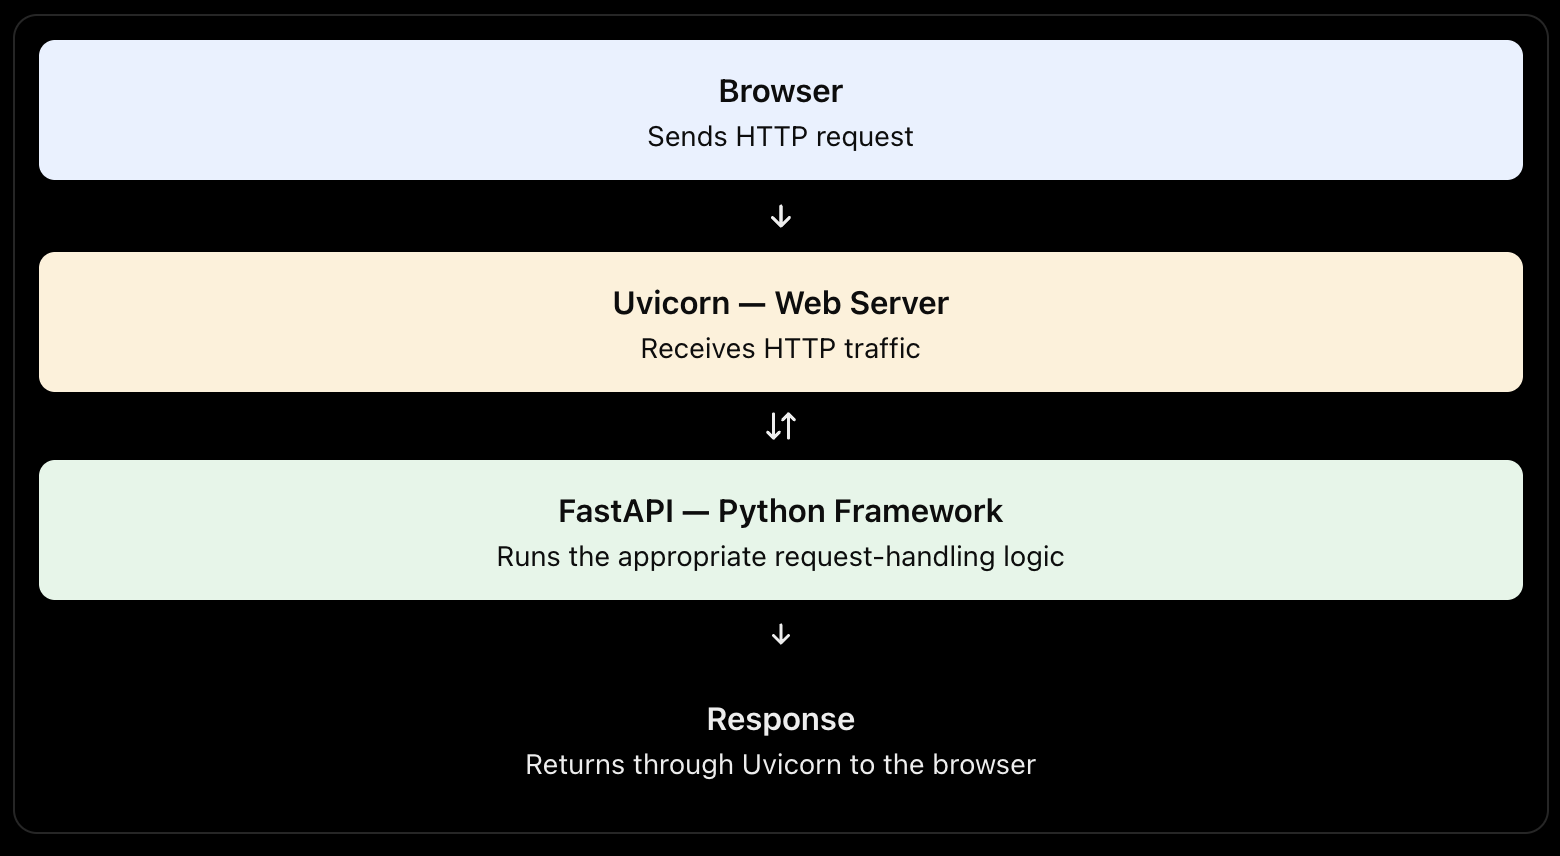

## 8A. What is a Framework?

A **framework** provides ready-made tools and structure to help us build applications easily.

**Example:** Imagine building a house. Without a framework, you build everything from scratch. With a framework, you get a basic structure and useful tools to work with.

In a web API, a framework helps us:
- Handle incoming requests.
- Connect URLs to Python functions.
- Validate data.
- Return responses and handle errors.
- Generate API documentation.

**Remember:** A framework handles common tasks so we can focus on our application logic.

In [ ]:
from http.server import BaseHTTPRequestHandler, HTTPServer
import json


class SimpleHandler(BaseHTTPRequestHandler):

    def do_GET(self):
        if self.path == "/":
            data = {"message": "Hello from Python"}

        elif self.path == "/employees":
            data = [
                {"id": 101, "name": "Ravi"},
                {"id": 102, "name": "Sita"},
            ]

        else:
            self.send_error(404, "Not Found")
            return

        body = json.dumps(data).encode("utf-8")

        self.send_response(200)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()

        self.wfile.write(body)


server = HTTPServer(("127.0.0.1", 8000), SimpleHandler)

print("Server running at http://127.0.0.1:8000")
server.serve_forever()

In [2]:
!pip install fastapi


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [3]:
from fastapi import FastAPI
app = FastAPI()

@app.get("/employees")
def get_employees():
    return [{"id": 101, "name": "Ravi"}, {"id": 102, "name": "Sita"}]


## 9. Why do Python web applications need WSGI or ASGI?

A web server receives an HTTP request, but the Python framework needs a standard way to receive that request and return a response. Without a shared interface, each server/framework combination would need its own integration.

Python's web ecosystem has standards for this connection. Two important ones are **WSGI** and **ASGI**.

```text
HTTP client
    |
    | HTTP
    v
Web / application server
    |
    | WSGI or ASGI interface
    v
Python web application
```

WSGI and ASGI are **interfaces between server software and Python web applications**. They are not HTTP methods, frameworks, or servers themselves.

## 10. WSGI – The Traditional Interface

**WSGI** stands for **Web Server Gateway Interface**.

Imagine a web server and a Python application speaking different languages. WSGI acts like a **common language** that helps them communicate.

Web server: A program that receives HTTP requests and passes them to the appropriate application.



Python application: A program that executes your business logic and decides what response to return.



WSGI: A standard way for these two programs to communicate.

### How does it work?

```text
Client
   ↓
Web Server
   ↓
  WSGI
   ↓
Python Application (Flask)
   ↓
  Response
```

**Why do we need it?**

WSGI provides a standard way for web servers to communicate with Python web applications.

**Limitation:** WSGI is designed mainly for traditional request-response applications. It doesn't natively support asynchronous features like WebSockets.

That's where **ASGI**, the modern interface used by FastAPI, comes in.

## 11. Why Was ASGI Introduced?

WSGI works well for traditional request-response applications, but modern applications also need features like **asynchronous operations and WebSockets**.

**Example:**
- **Chat application:** Users send and receive messages in real time.
- **Live notifications:** Updates arrive without refreshing the page.
- **Async API:** The application waits for a database or external API response without unnecessarily blocking other tasks.

**ASGI** stands for **Asynchronous Server Gateway Interface**. It supports asynchronous applications and protocols such as HTTP and WebSockets.

**Remember:**
- **WSGI:** Traditional Python web application interface.
- **ASGI:** Supports asynchronous applications and long-lived connections.

Async can improve efficiency when an application spends time waiting for network or database operations. It does not automatically make every API faster.

## 12. WSGI vs ASGI

| Topic | WSGI | ASGI |
|---|---|---|
| Full name | Web Server Gateway Interface | Asynchronous Server Gateway Interface |
| Main role | Standard interface for Python web applications | Standard interface for Python web applications |
| Model | Traditionally synchronous | Supports asynchronous applications |
| Protocol/use cases | Traditional HTTP request/response | HTTP and WebSockets, among other supported protocols |
| Common ecosystem | Many traditional Flask/Django deployments | FastAPI, Starlette, and other ASGI applications |

**Important nuance:** Django can be deployed with WSGI or ASGI, and Flask has gained async support in certain contexts. The main point is that FastAPI is designed around ASGI.

## 13. What is FastAPI, and what does a framework give us?

**FastAPI is a Python web framework designed for building APIs.** It lets us define a route with a decorator and a Python function rather than manually parsing every request and constructing every response.

Compare the manual work in `raw_server.py` with this FastAPI version:

```python
from fastapi import FastAPI

app = FastAPI()


@app.get("/")
def home():
    return {"message": "Hello from FastAPI"}


@app.get("/employees")
def get_employees():
    return [
        {"id": 101, "name": "Ravi"},
        {"id": 102, "name": "Sita"},
    ]
```

FastAPI provides routing and handles converting returned dictionaries/lists to JSON responses. It also integrates with Pydantic for data validation, supports dependency injection, and generates OpenAPI documentation.

The framework does not mean we never think about HTTP. We still choose routes, methods, status codes, data contracts, and security behavior. FastAPI makes the implementation more convenient and consistent.

## 13A. Flask vs Django vs FastAPI

Python provides different web frameworks for building websites and APIs.

| Framework | Simple explanation | Best suited for |
|---|---|---|
| **Flask** | Lightweight and flexible | Small web apps and APIs |
| **Django** | Comes with many built-in features | Full websites with authentication, database ORM, and admin panel |
| **Django REST Framework (DRF)** | Helps build APIs using Django | APIs in existing or new Django projects |
| **FastAPI** | Designed with a strong focus on APIs | APIs with data validation, async support, and automatic documentation |

### Which one should we choose?

- Need a full website with many built-in features? → **Django**
- Need a lightweight, flexible framework? → **Flask**
- Need APIs within a Django project? → **DRF**
- Need an API with type-based validation and automatic documentation? → **FastAPI**

**Remember:**
- Flask can build APIs too.
- Django and FastAPI are frameworks, not databases.
- FastAPI is not automatically faster in every situation; performance depends on how the application is built and deployed.

## 14. The complete request-response journey

Put the pieces together:

```text
1. Client wants employee data
          |
          | HTTP request: GET /employees
          v
2. Uvicorn receives the network request
          |
          | ASGI interface
          v
3. FastAPI receives the request
          |
          | matches method + path
          v
4. The matching endpoint function runs
          |
          | returns data
          v
5. FastAPI creates an HTTP response
          |
          v
6. Uvicorn sends the response to the client
```

Starlette supplies underlying web/ASGI capabilities, and Pydantic helps with data validation/serialization when schemas are involved. This is a conceptual diagram; internal processing has additional details.


## What are HTTP status codes?

Whenever a client sends an HTTP request, the server returns a response containing a status code.

For example, when you request `/employees`, the API might return `200 OK`. If you request a nonexistent employee, it should return `404 Not Found`.

| Status code                | Meaning                      | Employee API example               |
| -------------------------- | ---------------------------- | ---------------------------------- |
| `200 OK`                   | Request successful           | Employee retrieved or updated      |
| `201 Created`              | Resource created             | Employee added                     |
| `204 No Content`           | Success, no response body    | Employee deleted                   |
| `400 Bad Request`          | Invalid request              | Invalid operation or business rule |
| `404 Not Found`            | Resource doesn't exist       | Employee ID not found              |
| `409 Conflict`             | Conflicts with existing data | Duplicate employee ID              |
| `422 Unprocessable Entity` | Request validation failed    | Invalid integer path parameter     |

FastAPI doesn't automatically choose `201` for every POST or `404` when an employee isn't found. You need to configure or raise the appropriate response.

## Import `status` and `HTTPException`

At the top of your `main.py`, update your imports:

```
from fastapi import FastAPI, Body, HTTPException, status
```

- `status` provides readable names for HTTP status codes.
- `HTTPException` allows you to stop execution and return an HTTP error response.

For example:

```
raise HTTPException(    status_code=status.HTTP_404_NOT_FOUND,    detail="Employee not found")
```

Response:

```
{
  "detail": "Employee not found"
}
```

The HTTP response status will be `404`, not `200`.
